In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Importing data.

train_data = pd.read_csv('data/raw/train.csv')
valid_data = pd.read_csv('data/raw/valid.csv')
test_data = pd.read_csv('data/raw/test.csv')

In [3]:
# Combining train, valid and test into a single dataframe for exploration.

all_data = pd.concat([train_data, valid_data, test_data], ignore_index=True)

In [4]:
# Checking a sample of the dataframe.

all_data.sample(10)

,text,label,source
121135,故事写得很精彩，不过我以为这事只能在小说里头出现。不然那杀手简直就是神了。,neutral,amazon_reviews_multi
96369,刚拿到手，马上上了油，一打就燃，手感和声音都还不错，应该是正品。,positive,amazon_reviews_multi
104698,挺不错的作品，一口气看完的，没惊艳到我，但也不乏吸引力,positive,amazon_reviews_multi
107071,用了两片，感觉补水效果挺好的，也是正品，送给朋友了几片，朋友用的也挺好的~,positive,amazon_reviews_multi
102239,实物收到比图片漂亮，骑着也挺顺畅，代步性价比不错。,positive,amazon_reviews_multi
106881,给老爸买的，拍照清楚美观，联网较快，爸爸很喜欢,positive,amazon_reviews_multi
111587,很实用，通俗易懂，看完对投资理财有了大致了解,positive,amazon_reviews_multi
105546,女孩喜欢公主，正好符合她的兴趣。物流啥的都很赞。,positive,amazon_reviews_multi
112356,我买的是中码居然也有点大，我身高182，80公斤。其他都挺好，布料穿着很舒服,positive,amazon_reviews_multi
86206,口感温和，比之前买的李施德林好很多，不会有刺激口腔黏膜的不适感。气味清新，按照它的使用说明，...,positive,amazon_reviews_multi


In [5]:
# Checking for missing values and confirm the data types of each column.

all_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 126000 entries, 0 to 125999
Data columns (total 3 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   text    126000 non-null  str  
 1   label   126000 non-null  str  
 2   source  126000 non-null  str  
dtypes: str(3)
memory usage: 2.9 MB


In [6]:
# Looking for duplicates.

duplicate_count = all_data.duplicated(subset=["text"]).sum()
print("Duplicate reviews:", duplicate_count)


Duplicate reviews: 2701


In [7]:
# Checking whether duplicates are short reviews such as 还行 (decent) or 好 (good) or just spam.

duplicates= all_data[all_data.duplicated(subset=['text'])]
duplicates.sample(10)


,text,label,source
20733,为什么给一星？对书没意见，吐槽的是亚马逊的包装！一共买了七本书，一个塑料袋一装就发货了，每次...,negative,amazon_reviews_multi
64133,其实保健品这种东西老美那儿都很便宜，我看了之前一个亚马逊买家的评论在iherb网站海淘的，首...,neutral,amazon_reviews_multi
57414,不想多说，没时间，全复制评论，我给每本书都做了星评，小于4星不推荐购买，5星书本人强烈推荐。...,neutral,amazon_reviews_multi
19801,亚马逊中国服务绝对垃圾， 1个月的订单没任何消息，还要客户自己电话查询，同样无果，投诉也渠道...,negative,amazon_reviews_multi
26931,乱码乱码，重复，排版乱七八糟，前几部都还好，最后这两部错别字也多，排版也乱，重重复复的,negative,amazon_reviews_multi
64977,选择pos机付款，但是快递员却说只能付现金。不止买了这一样东西，那要是没现金付钱呢？不是第一...,neutral,amazon_reviews_multi
36644,亚马逊和电信诈骗配合得太好，买本书被骗子坑一大笔。,negative,amazon_reviews_multi
97382,很好，以前从不去评价，不知道浪费了多少积分，现在知道积分可以换钱，就要好好评价了，后来我就把...,positive,amazon_reviews_multi
65856,节奏比较快的书寒假买回来给小孩玩的，蛮可以的，不过就是玩玩，也别指望 学到什么,neutral,amazon_reviews_multi
71273,价格有点儿贵了，东西还可以，要是再低一点价格就好了。,neutral,amazon_reviews_multi


In [ ]:
# Checking the label composition of the raw data, before removing duplicates.
# Each label has exactly 42,000 reviews, so the dataset is balanced by construction.

all_data.groupby('label').size()

label
negative    42000
neutral     42000
positive    42000
dtype: int64

In [8]:
# Removing duplicate reviews, keeping only the first occurrence of each repeated text.

df= all_data.drop_duplicates(subset=['text'], keep='first')

In [ ]:
# Checking label's composition.
# The three labels are no longer identical in size, but remain close to balanced.
df.groupby('label').size()

label
negative    40619
neutral     41496
positive    41184
dtype: int64

In [10]:
# Calculating the lenght of each review in characters with a for loop.
# Chinese doesn't use space between words, so len() function is perfect for the purpose. 

reviews_length = []
for review in df['text']:
    length = len(review)
    reviews_length.append(length)

df['reviews_length'] = reviews_length #Creating new column

In [11]:
# Sorting all reviews by lenght, from shortest to longest.
# Checking short reviews whether they are meaningful or just empty or spam.

df.sort_values('reviews_length', ascending=True).head(20)

,text,label,source,reviews_length
58507,多加点角色 有趣 好了,neutral,amazon_reviews_multi,11
105356,很好的散文。 喵喵 喵,positive,amazon_reviews_multi,11
24037,没货！！！！！！ 没货,negative,amazon_reviews_multi,11
23738,不好 删也删不掉 不好,negative,amazon_reviews_multi,11
104541,也是大师作品。 名家作品,positive,amazon_reviews_multi,12
82727,很喜欢 好用的 简单易用,positive,amazon_reviews_multi,12
75228,不错，就是太啰嗦了 呵呵,neutral,amazon_reviews_multi,12
117219,不错 很不错 非常不错！,positive,amazon_reviews_multi,12
8624,这个真的一般般了 。 。,negative,amazon_reviews_multi,12
29060,视频花 没有客服解决 差,negative,amazon_reviews_multi,12


In [12]:
# Checking summary statistics for review length, to spot potential outliers.

df['reviews_length'].describe()

count    123299.000000
mean         50.667069
std          44.466860
min          11.000000
25%          26.000000
50%          37.000000
75%          58.000000
max        2377.000000
Name: reviews_length, dtype: float64

In [13]:
# Checking the longest reviews for anomalies, such as spam or repeated text.

df.sort_values('reviews_length', ascending=False).head(20)

,text,label,source,reviews_length
21539,"我的订单ORDER # C01-8336251-6185665被无故取消,不知道为什么?我的...",negative,amazon_reviews_multi,2377
14271,亚马逊、顺丰、风巢无视客户利益、效率低下、从不主动回复、推脱责任。投诉内容：1. 贵司未经本...,negative,amazon_reviews_multi,1378
87096,质量太差了，草，还不给评价！！质量太差了，草，还不给评价！！质量太差了，草，还不给评价！！质...,positive,amazon_reviews_multi,1333
32921,此乃黑商户，买了一次，每个月给你发次货，而且还不能退货！！！此乃黑商户，买了一次，每个月给你...,negative,amazon_reviews_multi,1230
4875,商品本身质量很好 但是 亚马逊的服务实在太差； 我们于 2018年7月14日下单为单位买了约...,negative,amazon_reviews_multi,1156
4554,如果可以给负分，我一定会给的。 这是一次极度让人不愉快的购物经历。 开始是因为急用，然后懒得...,negative,amazon_reviews_multi,1044
29464,如果可以给负分，我一定会给的。 这是一次极度让人不愉快的购物经历。 开始是因为急用，然后懒得...,negative,amazon_reviews_multi,1012
4372,同批买了一本书，但我有话说，因为太气愤了，我买了一本料理摆盘的书，这本书买了一个月，书没有寄...,negative,amazon_reviews_multi,942
2770,无良商家坑蒙骗，是转基因的但是没有标注！无良商家坑蒙骗，是转基因的但是没有标注！无良商家坑蒙...,negative,amazon_reviews_multi,920
119063,阅读此书纯属偶然，之前闻所未闻。看罢有种荡气回肠的感觉，觉得有时间还要再读一遍。 本书文中略...,positive,amazon_reviews_multi,868


In [14]:
# Comparing the two texts in full to see where they actually differ (index: 4554 and 29464)
text_a = df.loc[4554, 'text']
text_b = df.loc[29464, 'text']

print(text_a)
print(text_b)

# The two texts are identical except for an extra sentence at the end of the first one, so they are not exact duplicates and were correctly kept by drop_duplicates().


如果可以给负分，我一定会给的。 这是一次极度让人不愉快的购物经历。 开始是因为急用，然后懒得出门买，想着第二天到也行的。就在亚马逊上买了。 1.结果第二天没能到。翻了好久页面才找到客服在哪里。我就去找客服问我的书为什么没到？ 客服说不好意思啊，帮您催单，明天一定到。然后还给我发短信说有什么事可以直接发送短信询问，她们会回复。这样我就不用在线找客服了。 于是我想着那好吧，可能是年后快递堆积了吧，明天到也可以。 2.第三天等了一天，东西还是没到。晚上六点突然收到亚马逊短信，说“由于未能与您取得联系，我们将尽快为您重新安排包裹配送。”我看到就急了。你什么时候跟我联系了？！！我就着急的在前面客服说的短信下面回复，结果没半个人理我。 无奈，又只能在线找客服。 这次客服的态度就不怎么样了。我跟她说明了问题，人家只跟我说不能保证什么时候送到。然后我真的非常生气，我问她你们亚马逊既然不能次日达，为什么这么有脸说自己次日达呢？！！ 最后客服勉强说会催单，明天能送到。呵呵。真的对你们一点都不抱希望了。 3.第四天倒是真的到了。 总结一下，这是一次让人非常愤怒非常心力交瘁的购物经历。既然你们第二天送不到，那就不要在页面上不要脸地写着明天送达啊！！ 在那么多的网购平台上买过东西，敢说自己次日达的如天猫超市，京东，当天某个时间前下单，人家就一定是次日达的。 我家既不是住在月亮上也不是偏远山区。 既然不是次日达，就老老实实写清楚发货时间未知，别耽误别人行不行？！你的时间是时间，别人的就不是了？？ 还有，我还在自营书店上面买了一本书。我24上午下的单吧，27还没发货。我中间试图催单。结果屌爆了的亚马逊在催单那里显示了一段非常让人不愉快的文字，大意是什么你知道吗？你可以催单，但是商家没有义务配合您。你可以取消重新选择更符合你需求的订单。呵呵。 在催了一天单无果后想了下亚马逊催单里的话，我就不想要这本书了。就干脆取消了订单。 结果27晚上取消的，半夜就给我发来短信说书已经发货了。真是太搞笑了。既然说的出这么有种的话那干嘛还做这么没种的事？？嗯？？ 对了，27号下午三点我在京东买了一个U盘，28号中午十二点就送到了我家门口。 再也不会在这里买东西了。搞笑。网上书店又不是只有你们这一家，同类型的书城还有当当呢。不想干别干啊。就你们这样的服务，快要被淘汰了吧。 我决定把跟你们生气的时候留着去淘宝发消息建议

In [15]:
# Checking whether a review contains a piece of text (split on Chinese punctuation) that repeats within the same review.
# They could likely indicates spam or a duplicate comment submitted by mistake.

import re
def spam_detector_v1(text):
    pieces = re.split('[， ！ 。]', text)
    cleaned_pieces = []
    for piece in pieces:
        if piece != '':
            cleaned_pieces.append(piece)
    already_seen= []
    for piece in cleaned_pieces:
        if piece in already_seen:
            return True
        else:
            already_seen.append(piece)
    return False

In [16]:
# Checking how many reviews contain internal repetition.

repetition_results = []
for text in df['text']:
    result = spam_detector_v1(text)
    repetition_results.append(result)


repeated_count = sum(repetition_results)
print(repeated_count)

1182


In [17]:
# Sample 1 of flagged reviews, to explore the composition of internal repetition cases.
sample_1 = df[repetition_results].sample(20, random_state=42)
for index in sample_1.index:
    print(f"Index {index} ({sample_1.loc[index, 'label']}):", sample_1.loc[index, 'text'])

Index 72795 (neutral): 我要的是白色，结果给我的是红色，而袋子上却赫然写着白色。减一星。 起毛球，减一星。 有钱买贵点的吧，一分钱一分货。
Index 104034 (positive): 为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书
Index 110612 (positive): 不错 这个价格值了 不错 这个价格值了不错 这个价格值了不错 这个价格值了不错 这个价格值了不错 这个价格值了不错 这个价格值了
Index 5495 (negative): 只有奇数课的录音，即1，3，5，7...类推。大骗子！应该是每课都有，现在只有一半的录音。无良商家！第一册总共有144课，只有73课的录音。2，3，4完还没看。
Index 93742 (positive): 非常满意！商品质量非常好，而且卖家发货速度也挺快的，非常满意！而且服务态度也很好，很到位的！总体感觉不错！
Index 31738 (negative): 书没到，书没到，我同时买了两本，好像弄反了，显示一本没到，其实一本已经到了
Index 97169 (positive): 花了80块买了一个摆设，没有任何驱动装置。 好在我儿子也不挑，没有回力功能或电力驱动功能，这个价格

In [18]:
# Sample 2 of flagged reviews, to see a wider variety of cases.
sample_2 = df[repetition_results].sample(20, random_state=7)
for index in sample_2.index:
    print(f"Index {index} ({sample_2.loc[index, 'label']}):", sample_2.loc[index, 'text'])


Index 3077 (negative): 坑钱的 货到家里之后 外包装完好 拆封之后耳机盒子是空的 里面没有耳机 呵呵 申请换货 了 不知道能不能给换 反正不抱什么希望了 呵呵
Index 118777 (positive): 第一次在美亚买东西，非常满意！没想到这么快就收到了，法压壶的质量完全OK，小巧精致，1人份刚刚好，非常满意
Index 123795 (negative): 使用频率很低，大小真的很合适，设计非常好，是用到过设计最好的包了，但是，但是，但是，没用几次，竟然从里面开线了，接缝地方直接散开了，而且没法修补，眼睁睁废掉了，怀疑就是山寨产品。
Index 110922 (positive): 本书的作者肯塔克是一个演讲家，从事总裁指导类型的工作。通过不断的学习和实际事例，作者总结了一些处世技巧。好的处世技巧，有效的人际关系，使个人在生活中，在工作中少了一些烦恼，事半功倍。好的处世技巧对现实社会中的个人的作用变得越来越重要。 本书通过十二个章节，向读者介绍了12种塑造有效人脉的处世技巧。简明扼要的提出有效人脉要求个人掌握的内容和做事方法。做自己，建立自己的人格魅力，明确社交的目标和方向，提高社交效率，积极的付出，显示自己的个性元素，主动地去社交，培养自己敏锐的洞察力，重视别人观念想法，突出自己的存在感温柔地与人相处，用心去建立情感，选择这些方法技巧可以在实践中提升自己处世的技巧，为自己处世提供了指导，可以不断实践。 这书的亮点，也是我感到好的地方是，每个章节后都有两页，通过相互两个人对待彼此的观点看法，让我看到了其实转变一下看法，多想想，也许有些事情就会改变，有些人就会成为自己人生中的知己，就不会那么的烦心。书中还通过提出一些问题，让读者进行思考，三思而行，多想想，多实践，不断提升吧。用心的对待彼此，经营自己的人际圈，经营自己的生活。
Index 46330 (neutral): 下面的三腿的小支架有些偏， 下面的三腿的小支架有些偏， 下面的三腿的小支架有些偏， 下面的三腿的小支架有些偏， 下面的三腿的小支架有些偏， 下面的三腿的小支架有些偏，
Index 125709 (positive): 为什么试卷没有配套，为什么试卷没有配套。我得另外买
Index 34247 (negative): 差劲，什么祛痘，假的，假的，连退货都不准，再也不在这里买

In [19]:
# Sample 3 of flagged reviews, to see a wider variety of cases.
sample_3 = df[repetition_results].sample(20, random_state=100)
for index in sample_3.index:
    print(f"Index {index} ({sample_3.loc[index, 'label']}):", sample_3.loc[index, 'text'])

Index 114710 (positive): 好，很好，书里的内容也不错，很好，买给家里孩子的，孩子很喜欢。
Index 40038 (neutral): 夏天的时候，因为不想煮牛奶就选择了这款，确实用冷牛奶一下子就泡软了，但是！！！泡一下子都泡碎了，软趴趴的，像糊糊一样，本人极不习惯这种没有嚼劲的食物，觉得这款很适合做小朋友的辅食。另外这款没有多大的味道，请不要配合脱脂牛奶食用！请不要配合脱脂牛奶食用！请不要配合脱脂牛奶食用！重要的事情说三遍！那个时候还买了一箱脱脂牛奶，为了不浪费粮食，吃的时候选择，选择加了蜂蜜，另外搭配/水果/红枣 /坚果/葡萄干等等。现在天气变冷了，然后我还没有吃完它，现在的方法是用热水泡一碗皇室麦片，加一块这个麦片，嗯，味道还可以接受，为神马我还有半盒没吃完！！
Index 67359 (neutral): 太小，太小，太小！小的像是给小人国配的。
Index 18953 (negative): 快递差！！快递差！！知道地方不送 每天推来推去 不及时送货 差评差评
Index 52360 (neutral): 根本没有usb3.0接口，一个都没有。 根本没有usb3.0接口，一个都没有。 根本没有usb3.0接口，一个都没有。 规格上写的两个，其实一个都没有。有这个需求的要注意啦，其它的没有什么问题。
Index 12076 (negative): 实在很怀疑商品是否德国制造，设计上存在巨大瑕疵。我不小心摔了一下，然后笔芯在笔头部分断裂之后，由于笔头是不能拆开的，后面的笔芯不能自动顶上去，整支笔就用不了！！用不了！！用不了！！愤怒的事情强调三遍！！
Index 123856 (negative): 我见过最恶心的出版社之一，最早的书名叫做《大清灭亡启示录(1894-1911)》 ，花城出版社; 第1版 (2013年12月1日)。3年后改个名字换成《晚清最后十八年》，花城出版社; 第1版 (2016年1月1日)。两本书的内容基本上就是一样的，换个书名接着卖。再也不买这个出版社的任何书籍！
Index 23304 (negative): 假货！假货！跟我自用的味道完全不一样。质地也非常稀！慎买！申请退货一个星期了，都不给我退货地址！而且根本不是亚马逊自营的商品，直接从广州发货！
Index 17700 (negative): 什么鬼东西，只

## Investigating internal text repetition (spam detection function)

The `spam_detector_v1` function flagged 1182 out of 123,299 reviews as containing
internal repetition, using a "seen anywhere in the text" check. Before
refining the detection logic, three reproducible samples of 20 flagged
reviews each were drawn and inspected (`random_state=42`, `random_state=7`,
`random_state=100`). Three categories emerged from this inspection.

### Category A: Spam
The entire review consists of the same chunk of text repeated at least
twice, with no additional content — this could be an accidental
duplication of the same comment.
Examples: 97586, 33183, 15263, 46330, 58719 (see cell below). Reviews such as
104034 and 16573 are also full repetitions, but their separators are irregular:
they are discussed in Category C.

In [20]:
# Printing full text of reviews where the entire review is a repeated chunk.

for index in [97586, 33183, 15263, 46330, 58719]:
    print(f"Index {index}:", df.loc[index, 'text'])

Index 97586: 很好很喜欢。很好很喜欢。很好很喜欢。很好很喜欢。
Index 33183: 假的！！！！！！！假的！！！！！！！假的！！！！！！！
Index 15263: 就是个摆件，，，就是个摆件，，，就是个摆件，，，
Index 46330: 下面的三腿的小支架有些偏， 下面的三腿的小支架有些偏， 下面的三腿的小支架有些偏， 下面的三腿的小支架有些偏， 下面的三腿的小支架有些偏， 下面的三腿的小支架有些偏，
Index 58719: 句型比较有用 句型比较有用 句型比较有用 句型比较有用


### Category B: false positives (rhetorical repetition)
Repetition is present, but either only part of the review is repeated, 
or the repeated chunk is too short to be meaningful spam. 
These cases look like intentional rhetorical devices rather than accidental duplication.
Examples: 112794, 22394, 12076, 123795, 67359 (see cell below).

Two examples are worth calling out specifically:

- **19015** ("内容很渣渣，很渣渣，很渣渣，重要的事情说三遍") is a
  real-world confirmation of this: the user repeats "很渣渣" (low
  quality) three times, then explicitly justifies it with a common Chinese
  saying, "重要的事情说三遍" ("important things are said three times") —
  confirming the repetition is an intentional rhetorical device, not an
  accidental duplicate.
- **104455** ("自由，自由，自由，自由，自由。。。。我们生活在充满自由和幸福的
  社会主义制度下...哇！！！！！！！！！！") repeats "自由" (freedom) five times
  hinting a sarcastic tone, followed by exaggerated punctuation —
  another case of deliberate rhetorical repetition, not spam.

In [21]:
# Printing full text of reviews where the repetition has a rhetorical purpose

for index in [112794, 22394, 12076, 123795, 67359]:
    print(f"Index {index}:", df.loc[index, 'text'])

Index 112794: 买了将近两年，非常好！还送货上楼梯楼9楼！赞！赞！赞！
Index 22394: 差评，差评，差评，内容不好，没参考价值，在网上就可以百度的纯理论内容
Index 12076: 实在很怀疑商品是否德国制造，设计上存在巨大瑕疵。我不小心摔了一下，然后笔芯在笔头部分断裂之后，由于笔头是不能拆开的，后面的笔芯不能自动顶上去，整支笔就用不了！！用不了！！用不了！！愤怒的事情强调三遍！！
Index 123795: 使用频率很低，大小真的很合适，设计非常好，是用到过设计最好的包了，但是，但是，但是，没用几次，竟然从里面开线了，接缝地方直接散开了，而且没法修补，眼睁睁废掉了，怀疑就是山寨产品。
Index 67359: 太小，太小，太小！小的像是给小人国配的。


### Category C: irregular separators
The samples show that separators are not always placed between the copies of
the repeated chunk:

- some copies are glued together, so the pieces mix the end of one copy with
  the start of the next (104034);
- some repeated units are pairs of phrases, A B A B A B (16573);
- one review has a space between every character (57638).

`spam_detector_v1` still flags these reviews, because at least one piece
repeats, but its pieces do not match the repeated chunk, so it cannot tell how
much of the review is repeated (first cell below).

If separators can be missing, a review made of copies glued together with no
separator at all stays a single block, and `spam_detector_v1` cannot flag it,
because there is nothing to compare. These reviews cannot appear in the samples
above, so the second cell below looks for them directly.


In [22]:
# Printing full text of reviews where the separators are irregular.

for index in [104034, 16573, 57638]:
    print(f"Index {index}:", df.loc[index, 'text'])

Index 104034: 为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书为了给自己的孩子取名字，所以买这个书
Index 16573: 没有索引 你影印个毛线啊 没有索引 你影印个毛线啊 没有索引 你影印个毛线啊
Index 57638: 还 没 有 看 呢 还 没 有 看 呢


In [23]:
# Looking for reviews that stay a single block after splitting, but are made of
# the same chunk repeated: spam_detector_v1 cannot flag them.

single_block_reviews = []
for index, text in zip(df.index, df['text']):
    pieces = re.split('[，！。 ]', text)
    cleaned_pieces = []
    for piece in pieces:
        if piece != '':
            cleaned_pieces.append(piece)

    if len(cleaned_pieces) == 1:
        match = re.fullmatch(r'(.+?)\1+', cleaned_pieces[0])
        if match != None and len(match.group(1)) >= 2:
            single_block_reviews.append(index)

print("Single-block reviews made of a repeated chunk:", len(single_block_reviews))
single_block_sample = df.loc[single_block_reviews].sample(10, random_state=42)
for index in single_block_sample.index:
    print(f"Index {index} ({single_block_sample.loc[index, 'label']}):", single_block_sample.loc[index, 'text'])

Single-block reviews made of a repeated chunk: 107
Index 99083 (positive): 很好用很好用很好用很好用很好用很好用很好用很好用很好用
Index 11714 (negative): 好像没有效果好像没有效果好像没有效果好像没有效果好像没有效果
Index 6932 (negative): 基本没什么用基本没什么用基本没什么用基本没什么用
Index 117333 (positive): 很好用很好用很好用很好用很好用很好用很好用很好用很好用很好用
Index 95216 (positive): 很好的教材很好的教材很好的教材很好的教材很好的教材很好的教材很好的教材很好的教材很好的教材很好的教材很好的教材很好的教材很好的教材很好的教材很好的教材很好的教材很好的教材很好的教材很好的教材很好的教材很好的教材很好的教材很好的教材很好的教材
Index 87923 (positive): 非常不错~我喜欢非常不错~我喜欢非常不错~我喜欢非常不错~我喜欢非常不错~我喜欢
Index 41173 (neutral): 非要绑定两个才能购买吗非要绑定两个才能购买吗
Index 63952 (neutral): 像是被开封过的像是被开封过的像是被开封过的
Index 115163 (positive): 好东西就是不一样好东西就是不一样好东西就是不一样好东西就是不一样
Index 14615 (negative): 垃圾中的战斗机垃圾中的战斗机垃圾中的战斗机垃圾中的战斗机垃圾中的战斗机垃圾中的战斗机垃圾中的战斗机垃圾中的战斗机


### Known linguistic limitation
Chinese uses word/phrase reduplication both to intensify meaning and to
soften it. The intensifying use is illustrated by review 94673:

"好书。我已经读了两遍。再读，再读，再读，再读。"
("Good book. I've already read it twice. Read it again, read it again,
read it again, read it again.")

The softening use works differently: repeating a verb makes the action
sound lighter or more casual, as in 看看 ("take a quick look" — not an
example from this dataset).

This is a legitimate grammatical and rhetorical pattern. Text-only rules can
measure how much of a review is repeated, but not why: a review made entirely
of intentional repetition looks the same as an accidental duplicate. This is a
known, accepted limitation of any purely mechanical approach. The cell below
shows this review.

In [24]:
# Printing review 94673 directly, as a real example of intentional emphasis through repetition (reduplication), rather than spam.

print(df.loc[94673, 'text'])

好书。我已经读了两遍。 再读，再读，再读，再读。


### Decision
Since the separators cannot be trusted, in `spam_detector_v2` they won't be considered.
The function removes punctuation and spaces, looks for the smallest chunk that
repeats immediately after itself from the start of the text, and flags
the review only if that chunk covers at least 90% of the text and is at
least 2 characters long. This is stricter than `spam_detector_v1`: it
excludes cases like 94673, 22394, 112794, 104455 and 19015, where the repeated
chunk is only a small part of a varied review.

Punctuation is removed only inside the function, to detect repetition.
The original `text` column is not modified.

In [25]:
import re

def spam_detector_v2(text):
    # Piece 1: remove Chinese, ASCII punctuation and spaces.
    compact_text = re.sub('[，！。？、；：,.!?;:~ ]', '', text)

    if compact_text == '':
        return False

    # Piece 2: find the smallest chunk that repeats immediately after itself,
    # starting from the beginning of the text.
    match = re.match(r'(.+?)\1+', compact_text)

    if match == None:
        return False

    # Piece 3: count how many times the repeated chunk appears, to check how much of the text it covers.
    repeated_chunk = match.group(1)
    occurrences = compact_text.count(repeated_chunk)
    covered_characters = occurrences * len(repeated_chunk)
    coverage = covered_characters / len(compact_text)

    # Final decision.
    if coverage >= 0.9 and len(repeated_chunk) >= 2:
        return True
    else:
        return False

In [26]:
# Testing spam_detector_v2 on reviews already inspected manually.
# Each pair is (index, expected result).

test_reviews = [
    (104034, True),   # repeated block with no separator between copies
    (16573, True),    # alternating pair repeated (A B A B A B)
    (99947, True),    # repeated chunk with a different tail
    (33183, True),    # short chunk repeated as the entire review
    (57638, True),    # space between every character (excess separators)
    (58719, True),    # copies separated by spaces
    (94673, False),   # rhetorical reduplication inside a varied review
    (19015, False),   # same as previous 
    (22394, False),   # repetition only at the start of a varied review
    (112794, False),  # repetition only at the end of a varied review
    (104455, False),  # sarcastic repetition followed by other content
]

for index, expected in test_reviews:
    text = df.loc[index, 'text']
    result = spam_detector_v2(text)
    if result == expected:
        status = "OK"
    else:
        status = "MISMATCH"
    print(f"Index {index}: got {result}, expected {expected} -> {status}")

Index 104034: got True, expected True -> OK
Index 16573: got True, expected True -> OK
Index 99947: got True, expected True -> OK
Index 33183: got True, expected True -> OK
Index 57638: got True, expected True -> OK
Index 58719: got True, expected True -> OK
Index 94673: got False, expected False -> OK
Index 19015: got False, expected False -> OK
Index 22394: got False, expected False -> OK
Index 112794: got False, expected False -> OK
Index 104455: got False, expected False -> OK


In [27]:
# Applying spam_detector_v2 to the entire dataset. 

genuine_spam_reviews = []
for text in df['text']:
    result = spam_detector_v2(text)
    genuine_spam_reviews.append(result)

genuine_spam_count = sum(genuine_spam_reviews)
print("Reviews classified as spam:", genuine_spam_count)

Reviews classified as spam: 383


In [28]:
# Sampling reviews flagged by spam_detector_v2, to check that they match the criterion.

flagged_reviews = []
for position, result in enumerate(genuine_spam_reviews):
    if result == True:
        flagged_reviews.append(position)

flagged_sample_v2 = df.iloc[flagged_reviews].sample(20, random_state=42)
for index in flagged_sample_v2.index:
    print(f"Index {index} ({flagged_sample_v2.loc[index, 'label']}):", flagged_sample_v2.loc[index, 'text'])

Index 94225 (positive): 不错，不错不错，不错不错，不错不错，不错不错，不错不错，不错不错，不错不错，不错不错，不错不错，不错
Index 87570 (positive): 质量很好，大爱质量很好，大爱质量很好，大爱
Index 106628 (positive): 很好合适。就是要剁手。很好合适。就是要剁手。
Index 110863 (positive): 可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的
Index 16728 (negative): 或者说不太实用或者说不太实用或者说不太实用
Index 121787 (neutral): 偶尔会掉线，不如08年买笔记本送的那个54M的偶尔会掉线，不如08年买笔记本送的那个54M的偶尔会掉线，不如08年买笔记本送的那个54M的
Index 9641 (negative): 浪费人民币！浪费人民币！浪费人民币！浪费人民币！浪费人民币！浪费人民币！浪费人民币！浪费人民币！浪费人民币！浪费人民币！浪费人民币！浪费人民币！
Index 34088 (negative): 我要发票我要发票我要发票我要发票我要发票我要发票我要发票我要发票我要发票
Index 122416 (positive): 完美完美完美完美完美完美完美完美完美完美完美完美完美完美完美完美完美完美完美
Index 84410 (positive): 非常好 非常好非常好 非常好非常好 非常好非常好 非常好
Index 86144 (positive): 多搞活动！多搞活动！多搞活动！多搞活动！
Index 36240 (negative): 没带书签，差评。 没带书签，差评。 没带书签，差评。
Index 68534 (neutral): 不错哦还可以不错哦还可以不错哦还可以不错哦还可以不错哦还可以
Index 89895 (positive): 好用，不错!好用，不错!好用，不错!好用，不错!
Index 32921 (negative): 此乃黑商户，买了一次，每个月给你发次货，而且还不能退货！！！此乃黑商户，买了一次，每个月给你发次货，而且还不能退货！！！此乃黑商户，买了一次，每个月给你发次货，而且还不

In [29]:
# Sampling reviews flagged by spam_detector_v1() but not by spam_detector_v2(),
# to check whether the stricter v2 criterion is missing genuine spam.

missed_spam_reviews = []
for position in range(len(repetition_results)):
    was_flagged_originally = repetition_results[position]
    is_flagged_now = genuine_spam_reviews[position]
    if was_flagged_originally == True and is_flagged_now == False:
        missed_spam_reviews.append(position)

print("Flagged originally but not by v2:", len(missed_spam_reviews))
missed_sample = df.iloc[missed_spam_reviews].sample(20, random_state=42)
for index in missed_sample.index:
    print(f"Index {index} ({missed_sample.loc[index, 'label']}):", missed_sample.loc[index, 'text'])

Flagged originally but not by v2: 922
Index 26086 (negative): 百思不得其解，百思不得其解，百思不得其解。海外自营啊。
Index 30185 (negative): 100 100 100 的盗版 书，盗版书 ，印刷 纸张 都是废纸 做的
Index 48817 (neutral): 一直纠结着宝宝的背带选哪个牌子，同时买了 ergobaby 和 boba carrier，对比后，还是选择留下了 boba carrier。 1、boba carrier 可以直接适用于新生儿，ergobaby 要加个内衬才可以适用于新生儿，对于炎热的夏天，加个内衬简直热到无法忍受。 2、boba carrier 的帽子可以完全收到前面的袋子里，ergobaby 的帽子因为连着背带的上沿，只能塞一半进去，既不好看又不方便。 3、boba carrier 的肩带有个固定妈妈包的搭扣，这个实在是太实用了，不用老是担心包包滑落。 当然 ergobaby 也有优点，据说 ergobaby 的有机棉更加凉爽透气，虽然没有体会到，但是手感上觉得 ergobaby 更舒服些。 其他使用方面两者差不多。
Index 24152 (negative): 产品无塑封，无发票，怀疑为假货！！！第一次买到盒子没有塑封的电子产品，而且没有开发票，怀疑为假货
Index 46542 (neutral): 做工尚可，就是味道有点怪怪的，做工尚可，类似硅胶的材质兼有防滑的特点。
Index 5397 (negative): 连着买了三个玩具！每次话也不说直接扔到楼下超市！！！冲这个快递我都不想再买亚马逊！！早知道一个人带孩子还得楼下拿快递多么不方便！第一次遇到这样的快递！差评！差评！！另外这个小榔头设计上不合理！打人手拿着正合适！小孩握不住太粗了！没有退货的习惯！
Index 40371 (neutral): 这鞋子1月初买的，我还没怎么穿呢，现在居然鞋底裂了，坑爹啊。。。太坑爹啦，才两个来月，怎么就裂了，没法穿啦！！！真缺德！！！鞋面还挺新呢，鞋底子完蛋了，也没法继续穿了啊！！！靠！！！无良的商家！！！真缺德！！！
Index 73981 (neutral): 不怎么样！孟加拉生产的，线头多，线头多！很一般…
Index 105293 (positive

## Cleaning spam reviews (spam_cleaner)
The 383 reviews flagged by `spam_detector_v2` are not removed: each one is
reduced to a single copy of the repeated chunk, so that its content can
still be used for sentiment analysis.

The approach uses a regex that captures the smallest chunk repeated from
the start of the review, allowing separators between copies. 
Whatever follows the repeated part (the "tail") would be lost if only
the chunk were kept. Before writing the cleaning function, the tails are inspected
to see what they contain.

In [30]:
# Checking what remains after the repeated part of the review (the "tail"),
# and whether it is just the beginning of another copy (truncated copy).

separators = '，！。？、；：,.!?;:~ '
tail_count = 0

for position in flagged_reviews:
    index = df.index[position]
    text = df.iloc[position]['text']
    match = re.match(r'(.+?)(?:[，！。？、；：,.!?;:~ ]*\1)+', text)

    if match != None:
        chunk = match.group(1)
        left_over = text[match.end():]
        cleaned_left_over = left_over.strip(separators)
        
        if cleaned_left_over != '':
            tail_count = tail_count + 1
            is_truncated_copy = chunk.startswith(cleaned_left_over)
            print(f"Index {index} ({df.iloc[position]['label']})")
            print("   chunk:", chunk)
            print("   tail: ", cleaned_left_over)
            print("   truncated copy:", is_truncated_copy)

print(f"Reviews with a non-empty tail: {tail_count}")

Index 7961 (negative)
   chunk: 不好
   tail:  不坏不好不好不好不好不好不好不好不好
   truncated copy: False
Index 11439 (negative)
   chunk: 灰色的
   tail:  哭
   truncated copy: False
Index 21539 (negative)
   chunk: 我的订单ORDER # C01-8336251-6185665被无故取消,不知道为什么
   tail:  我
   truncated copy: True
Index 26657 (negative)
   chunk: 才买了几天就下浮了300大洋，东西也是别人退货的发给我。其他家的发票还在里面
   tail:  什么玩意
   truncated copy: False
Index 34269 (negative)
   chunk: 用了一个月就基本充不进电了，2个月不到，彻底坏了
   tail:  重要的事情说四遍
   truncated copy: False
Index 35148 (negative)
   chunk: 有点小 很硬
   tail:  v
   truncated copy: False
Index 37370 (negative)
   chunk: 质量太差了，三个月不到就开胶了
   tail:  亚马逊，这个怎么处理
   truncated copy: False
Index 46435 (neutral)
   chunk: 亚马逊的包邮条件越来越贵 包装质量越来越差 我买了五本书 四本书先发 这么厚一堆 你好意思给我一层胶纸口袋就装了 连泡泡纸都没得了呵呵哒
   tail:  重要的话要说三遍
   truncated copy: False
Index 47442 (neutral)
   chunk: 为什么有些资讯看不见
   tail:  为什么有些资讯为什么有些资讯看不见？为什么有些资讯看不见为什么有些资讯看不见为什么有些资讯看不见为什么有些资讯看不见为什么有些资讯看不见为什么有些资讯看不见为什么有些资讯看不见为什么有些资讯看不见为什么有些资讯看不见为什么有些资讯看不见为什么有些资讯看不见
   truncate

### Decision
The inspection above shows 11 reviews with a non-empty tail:
- 8 tails add real content (e.g. 98514: 真的非常喜欢 "I really like it a lot";
  7961: 不坏 "not bad", which reverses the meaning of the repeated
  不好 "not good"), so they are kept in the cleaned text;
- 1 tail is a truncated copy of the chunk (21539: 我 "I", the first
  character of the repeated sentence), so it is removed from the cleaned
  text (the review itself stays in the dataset);
- the remaining 2 (35148, 47442) are discussed in the limitations below.

`spam_cleaner` therefore handles three cases:
1. **Empty tail**: only punctuation follows the repeated part, so the
   final punctuation is kept in the cleaned text.
2. **Truncated copy**: the tail is the beginning of the chunk, so it is
   removed from the cleaned text.
3. **Meaningful tail**: anything else is kept in the cleaned text.

Known limitations:
- 47442: copies are interrupted in the middle and restart, so most of the
  text ends up in the tail.
- 35148: the tail is a single letter (v), probably a typo, kept as content.
- 34269 ends with 重要的事情说四遍 ("important things are said four times")
  and 46435 with 重要的话要说三遍 ("important words must be said three
  times"). In both cases the number declared matches the number of copies
  (4 and 3): the repetition is clearly intentional, as in 19015, but
  massive enough to pass the 90% coverage threshold of
`spam_detector_v2` (91.7% and 95.9%; see below).


In [31]:
# Printing full text of reviews where the user declares the repetition intentional,
# and computing the coverage of the repeated chunk (same steps as spam_detector_v2).

for index in [34269, 46435]:
    text = df.loc[index, 'text']

    # Same steps as spam_detector_v2: remove punctuation and spaces, find the repeated chunk.
    compact_text = re.sub('[，！。？、；：,.!?;:~ ]', '', text)
    match = re.match(r'(.+?)\1+', compact_text)
    repeated_chunk = match.group(1)

    occurrences = compact_text.count(repeated_chunk)
    covered_characters = occurrences * len(repeated_chunk)
    coverage = covered_characters / len(compact_text)
    
    print(f"Index {index}:", text)
    print(f"    copies of the chunk: {occurrences}")
    print(f"    coverage: {coverage}")

Index 34269: 用了一个月就基本充不进电了，2个月不到，彻底坏了用了一个月就基本充不进电了，2个月不到，彻底坏了用了一个月就基本充不进电了，2个月不到，彻底坏了用了一个月就基本充不进电了，2个月不到，彻底坏了，重要的事情说四遍
    copies of the chunk: 4
    coverage: 0.9166666666666666
Index 46435: 亚马逊的包邮条件越来越贵 包装质量越来越差 我买了五本书 四本书先发 这么厚一堆 你好意思给我一层胶纸口袋就装了 连泡泡纸都没得了呵呵哒 亚马逊的包邮条件越来越贵 包装质量越来越差 我买了五本书 四本书先发 这么厚一堆 你好意思给我一层胶纸口袋就装了 连泡泡纸都没得了呵呵哒 亚马逊的包邮条件越来越贵 包装质量越来越差 我买了五本书 四本书先发 这么厚一堆 你好意思给我一层胶纸口袋就装了 连泡泡纸都没得了呵呵哒 重要的话要说三遍
    copies of the chunk: 3
    coverage: 0.9587628865979382


In [32]:
# Reducing a spam review to a single copy of the repeated chunk,
# keeping the tail only when it adds new content.

def spam_cleaner(text):
    # Piece 1: find the smallest chunk that repeats, allowing separators between copies.
    match = re.match(r'(.+?)(?:[，！。？、；：,.!?;:~ ]*\1)+', text)

    if match == None:
        return text

    # Piece 2: split the review into the repeated chunk and what follows the last full copy.
    cleaned = match.group(1)
    left_over = text[match.end():]
    cleaned_left_over = left_over.strip('，！。？、；：,.!?;:~ ')

    # Handling the three cases
    if cleaned_left_over == '':
        # Empty tail: keep the final punctuation.
        return cleaned + left_over
    elif cleaned.startswith(cleaned_left_over):
        # Truncated copy: drop it.
        return cleaned
    else:
        # Meaningful tail: keep it.
        return cleaned + left_over

### Testing spam_cleaner
The test cases cover each branch of the function:
- **Empty tail** (97586 from Category A, 9641 from the v2 sample):
  only punctuation follows the repeated part, so the final punctuation
  is kept in the cleaned text.
- **Truncated copy** (21539): the tail is the beginning of the repeated
  chunk, so it is removed from the cleaned text.
- **Meaningful tail** (98514, 99947, 11439, 7961): the tail adds new content,
  so it is kept in the cleaned text.

In [33]:
# Testing spam_cleaner on reviews with different kinds of tail.
# Each pair is (index, expected cleaned text).

cleaner_tests = [
    (98514, '非常喜欢。真的非常喜欢。'),               # tail with real content
    (99947, '喜欢就买。就是喜欢就买。'),               # tail with real content
    (11439, '灰色的。。。哭。。。'),                   # short but meaningful tail
    (7961, '不好不坏不好不好不好不好不好不好不好不好。。。。。。。。。'),  # tail reverses the meaning (不坏)
    (21539, '我的订单ORDER # C01-8336251-6185665被无故取消,不知道为什么'),  # truncated copy, dropped
    (97586, '很好很喜欢。'),                         # no tail, punctuation kept
    (9641, '浪费人民币！'),                          # no tail, punctuation kept
]

for index, expected in cleaner_tests:
    result = spam_cleaner(df.loc[index, 'text'])
    if result == expected:
        status = "OK"
    else:
        status = "MISMATCH"
    print(f"Index {index}: {status}")
    if status == "MISMATCH":
        print("   got:     ", result)
        print("   expected:", expected)

Index 98514: OK
Index 99947: OK
Index 11439: OK
Index 7961: OK
Index 21539: OK
Index 97586: OK
Index 9641: OK


In [34]:
# Comparing original and cleaned text on a sample of flagged reviews.

flagged_sample = df.iloc[flagged_reviews].sample(20, random_state=42)
for index in flagged_sample.index:
    text = flagged_sample.loc[index, 'text']
    print(f"Index {index}")
    print(f"   original: {text}")
    print(f"   cleaned:  {spam_cleaner(text)}")

Index 94225
   original: 不错，不错不错，不错不错，不错不错，不错不错，不错不错，不错不错，不错不错，不错不错，不错不错，不错
   cleaned:  不错
Index 87570
   original: 质量很好，大爱质量很好，大爱质量很好，大爱
   cleaned:  质量很好，大爱
Index 106628
   original: 很好合适。就是要剁手。很好合适。就是要剁手。
   cleaned:  很好合适。就是要剁手。
Index 110863
   original: 可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的
   cleaned:  可以的
Index 16728
   original: 或者说不太实用或者说不太实用或者说不太实用
   cleaned:  或者说不太实用
Index 121787
   original: 偶尔会掉线，不如08年买笔记本送的那个54M的偶尔会掉线，不如08年买笔记本送的那个54M的偶尔会掉线，不如08年买笔记本送的那个54M的
   cleaned:  偶尔会掉线，不如08年买笔记本送的那个54M的
Index 9641
   original: 浪费人民币！浪费人民币！浪费人民币！浪费人民币！浪费人民币！浪费人民币！浪费人民币！浪费人民币！浪费人民币！浪费人民币！浪费人民币！浪费人民币！
   cleaned:  浪费人民币！
Index 34088
   original: 我要发票我要发票我要发票我要发票我要发票我要发票我要发票我要发票我要发票
   cleaned:  我要发票
Index 122416
   original: 完美完美完美完美完美完美完美完美完美完美完美完美完美完美完美完美完美完美完美
   cleaned:  完美
Index 84410
   original: 非常好 非常好非常好 非常好非常好 非常好非常好 非常好
   cleaned:  非常好
Index 86144
   original: 多搞活动！多搞活动！多搞活动！多搞活动！
   cleaned:  多搞活动！
Index 36240
   original

In [35]:
# Adding a column that marks the reviews flagged by spam_detector_v2.

df['is_repeated'] = genuine_spam_reviews

In [36]:
# Building the cleaned text for every review: spam reviews are reduced to a single copy with spam_cleaner,
# while all the other reviews are kept as they are.

cleaned_text = []
for rev, text in zip(df['is_repeated'], df['text']):
    if rev == True:
        to_clean_text= spam_cleaner(text)
        cleaned_text.append(to_clean_text)
    else:
        cleaned_text.append(text)

In [37]:
# Verifying that the cleaned text list has one element per review, so it can be added as a new column.

print(len(cleaned_text))

123299


In [38]:
# Saving the cleaned text in a new column, next to the original text.

df['clean_text'] = cleaned_text

In [39]:
# Checking a sample of repeated reviews, to compare the original and the cleaned text.

repeated_sample = df[df['is_repeated']].sample(10, random_state=42)
for index in repeated_sample.index:
    print(f"Index {index} ({repeated_sample.loc[index, 'label']})")
    print(f"   text:       {repeated_sample.loc[index, 'text']}")
    print(f"   clean_text: {repeated_sample.loc[index, 'clean_text']}")

Index 94225 (positive)
   text:       不错，不错不错，不错不错，不错不错，不错不错，不错不错，不错不错，不错不错，不错不错，不错不错，不错
   clean_text: 不错
Index 87570 (positive)
   text:       质量很好，大爱质量很好，大爱质量很好，大爱
   clean_text: 质量很好，大爱
Index 106628 (positive)
   text:       很好合适。就是要剁手。很好合适。就是要剁手。
   clean_text: 很好合适。就是要剁手。
Index 110863 (positive)
   text:       可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的可以的
   clean_text: 可以的
Index 16728 (negative)
   text:       或者说不太实用或者说不太实用或者说不太实用
   clean_text: 或者说不太实用
Index 121787 (neutral)
   text:       偶尔会掉线，不如08年买笔记本送的那个54M的偶尔会掉线，不如08年买笔记本送的那个54M的偶尔会掉线，不如08年买笔记本送的那个54M的
   clean_text: 偶尔会掉线，不如08年买笔记本送的那个54M的
Index 9641 (negative)
   text:       浪费人民币！浪费人民币！浪费人民币！浪费人民币！浪费人民币！浪费人民币！浪费人民币！浪费人民币！浪费人民币！浪费人民币！浪费人民币！浪费人民币！
   clean_text: 浪费人民币！
Index 34088 (negative)
   text:       我要发票我要发票我要发票我要发票我要发票我要发票我要发票我要发票我要发票
   clean_text: 我要发票
Index 122416 (positive)
   text:       完美完美完美完美完美完美完美完美完美完美完美完美完美完美完美完美完美完美完美
   clean_text: 完美
Index 84410 (positive)
  

### A note on terminology: what "spam" means here
In its usual sense, spam is unsolicited content sent in bulk, which does not
describe reviews written by customers about their own purchase. In this notebook,
*spam* is only a technical label: one chunk covers at least 90% of the review.
The label describes the form of the text, not the customer's intent: reviews
34269 and 46435 meet the criterion but declare the repetition intentional.
The function names keep this label, and the `is_repeated` column describes the same form.

The purpose of the repetition cannot be determined from the text alone, but
three explanations are possible:
- **emphasis**: the customer repeats the message on purpose (34269 and 46435:
  重要的事情说四遍 / 重要的话要说三遍);
- **rewards**: some Chinese e-commerce platforms reward reviews that reach
  a minimum length, which can lead customers to pad their text;
- **technical errors**: a double submission or a copy-paste mistake.

## Label distribution of flagged reviews
Are reviews with full repetition more positive, negative or neutral than the
rest of the dataset? Since the classes are balanced by construction, the
comparison uses percentages within each group.

In [40]:
# Counting the labels among the reviews flagged by spam_detector_v2.
flagged_labels = df[genuine_spam_reviews].groupby('label').size()
print(flagged_labels)

label
negative    137
neutral      90
positive    156
dtype: int64


In [41]:
# Converting the counts into percentages, to compare them with the whole dataset.
flagged_total = flagged_labels.sum()
flagged_percentage = (flagged_labels / flagged_total)*100
print(round(flagged_percentage, 2))

label
negative    35.77
neutral     23.50
positive    40.73
dtype: float64


In [42]:
# Computing the label percentages on the whole dataset, as a baseline for comparison.
all_labels = df.groupby('label').size() 
all_labels_total = all_labels.sum()
all_labels_percentage = (all_labels / all_labels_total)*100 
print(round(all_labels_percentage, 2))

label
negative    32.94
neutral     33.65
positive    33.40
dtype: float64


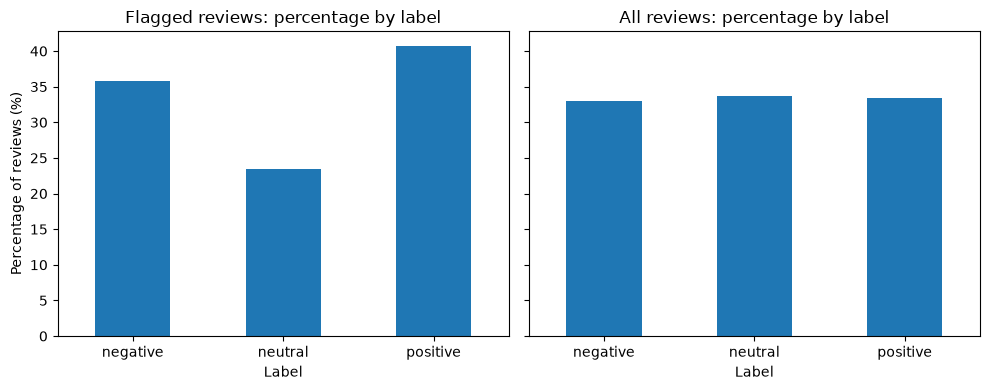

In [43]:
# Plotting the label percentages of flagged reviews and of the whole dataset side by side.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

flagged_percentage.plot(kind='bar', ax=ax1, rot=0)
ax1.set_title('Flagged reviews: percentage by label')
ax1.set_xlabel('Label')
ax1.set_ylabel('Percentage of reviews (%)')

all_labels_percentage.plot(kind='bar', ax=ax2, rot=0)
ax2.set_title('All reviews: percentage by label')
ax2.set_xlabel('Label')

plt.tight_layout()
plt.show()

Flagged reviews are clearly less neutral than the whole dataset (23.5% vs
33.7%), and more often positive (40.7% vs 33.4%). Negative reviews are only
slightly higher (35.8% vs 32.9%), a small gap on just 383 reviews, so it does
not support strong conclusions. Since the dataset is balanced by construction,
these percentages only allow a comparison within it: they do not show how common
each label is on Amazon.

In [44]:
# Measuring, for every flagged review, the length of the repeated chunk and how many times it is copied,
# together with the review label.

flagged_reviews_labels = []
chunk_length = []
copies_count = []

for position in flagged_reviews:
    text = df.iloc[position]['text']
    label = df.iloc[position]['label']

    compact_text = re.sub('[，！。？、；：,.!?;:~ ]', '', text)
    match = re.match(r'(.+?)\1+', compact_text)
    repeated_chunk = match.group(1)
    repeated_chunk_length = len(repeated_chunk)
    occurrences = compact_text.count(repeated_chunk)

    flagged_reviews_labels.append(label)
    chunk_length.append(repeated_chunk_length)
    copies_count.append(occurrences)

In [45]:
# Building a dataframe with one row per flagged review.

repetition_data = pd.DataFrame({
    'label': flagged_reviews_labels,
    'chunk_length': chunk_length,
    'copies': copies_count
})

repetition_data.head()

,label,chunk_length,copies
0,negative,17,6
1,negative,2,5
2,negative,29,2
3,negative,17,3
4,negative,5,5


In [46]:
# Verifying the number of reviews.

repetition_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 383 entries, 0 to 382
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   label         383 non-null    str  
 1   chunk_length  383 non-null    int64
 2   copies        383 non-null    int64
dtypes: int64(2), str(1)
memory usage: 9.1 KB


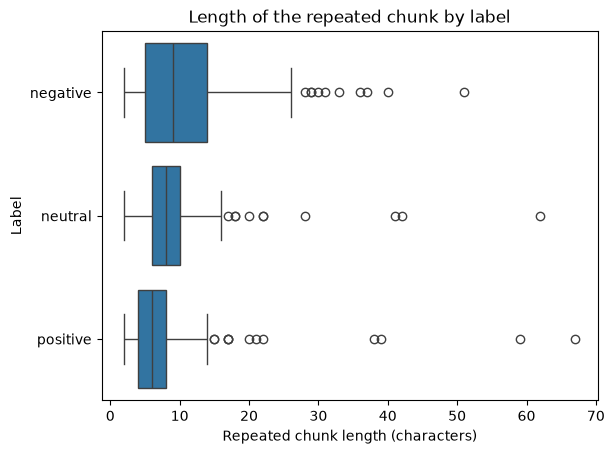

In [47]:
# Plotting the length of the repeated chunk by label.

ax = sns.boxplot(data=repetition_data, x='chunk_length', y='label', order=['negative', 'neutral', 'positive'])
ax.set_title('Length of the repeated chunk by label')
ax.set_xlabel('Repeated chunk length (characters)')
ax.set_ylabel('Label')

plt.show()

In [48]:
# Computing median and quartiles of the repeated chunk length by label.

repetition_data.groupby('label')['chunk_length'].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
negative,137.0,11.416058,8.833960,2.0,5.0,9.0,14.0,51.0
neutral,90.0,9.977778,8.781976,2.0,6.0,8.0,10.0,62.0
positive,156.0,7.487179,8.227011,2.0,4.0,6.0,8.0,67.0


Positive reviews tend to repeat shorter chunks: the median length is 6
characters, and 75% of positive chunks are no longer than 8 characters
(including single words such as 完美 "perfect" or 不错 "not bad"). Negative and
neutral reviews repeat longer chunks, with similar medians (9 and 8
characters). Negative chunks are the most variable, with an interquartile
range of 9 characters (from 5 to 14), against 4 for neutral (6 to 10) and
positive (4 to 8) chunks, suggesting full sentences rather than single words.

In all three groups most chunks are short, with a few much longer ones
(up to 51, 62 and 67 characters for negative, neutral and positive reviews), and the distributions overlap considerably:
the difference between groups is a tendency; there is no clear separation.

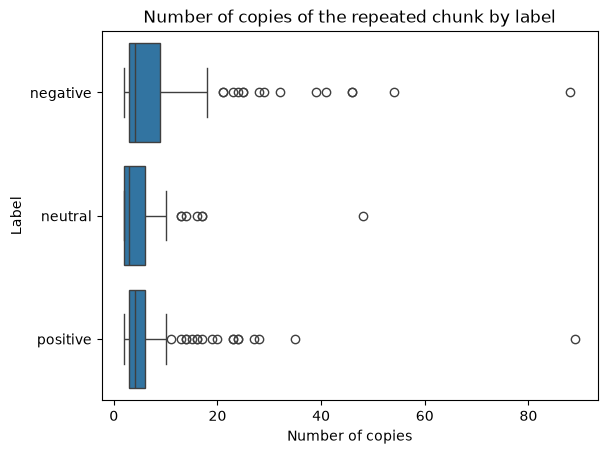

In [49]:
# Plotting the number of copies of the repeated chunk by label.

ax = sns.boxplot(data=repetition_data, x='copies', y='label', order=['negative', 'neutral', 'positive'])
ax.set_title('Number of copies of the repeated chunk by label')
ax.set_xlabel('Number of copies')
ax.set_ylabel('Label')

plt.show()

In [50]:
# Computing median and quartiles of the number of copies by label.
repetition_data.groupby('label')['copies'].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
negative,137.0,8.635036,11.792867,2.0,3.0,4.0,9.0,88.0
neutral,90.0,5.122222,5.772519,2.0,2.0,3.0,6.0,48.0
positive,156.0,6.339744,8.753614,2.0,3.0,4.0,6.0,89.0


Neutral reviews repeat their chunk the fewest times (median 3 copies,
against 4 for negative and positive reviews). Negative reviews are the most
variable (interquartile range from 3 to 9 copies), while positive reviews
are the most regular (3 to 6 copies) but include the most extreme case
(89 copies).


### Summary: what repeated reviews look like
- **Repetition goes with fewer neutral reviews.** Reviews with full repetition
  are much less often neutral than the whole dataset (23.5% vs 33.7%) and more
  often positive (40.7% vs 33.4%). The gap for negative reviews (35.8% vs 32.9%)
  is too small to support strong conclusions.
- **Negative reviews repeat longer chunks.** Their chunks are the longest and
  the most variable (median 9 characters, interquartile range from 5 to 14).
  The number of copies also varies the most (median 4, as in positive reviews,
  with an interquartile range from 3 to 9).
- **Positive reviews repeat shorter chunks.** Their median is 6 characters, and
  75% have at most 8, including words such as 完美 "perfect" or 不错 "not bad".
  They are usually repeated 3 to 6 times, with some extreme cases (up to 89 copies).

These patterns are tendencies, not clear separations: the three groups
overlap considerably. They are consistent with repetition being used to
vent dissatisfaction in negative reviews and to add emphasis in positive
ones, but the text alone cannot confirm the user's intent.

In [51]:
df.head(5)

,text,label,source,reviews_length,is_repeated,clean_text
0,本人账号被盗，资金被江西（杨建）挪用，请亚马逊尽快查实，将本人的200元资金退回。本人已于2...,negative,amazon_reviews_multi,98,False,本人账号被盗，资金被江西（杨建）挪用，请亚马逊尽快查实，将本人的200元资金退回。本人已于2...
1,这简直就是太差了！出版社怎么就能出版吗？我以为是百度摘录呢！这到底是哪个鱼目混珠的教授啊？！...,negative,amazon_reviews_multi,116,False,这简直就是太差了！出版社怎么就能出版吗？我以为是百度摘录呢！这到底是哪个鱼目混珠的教授啊？！...
2,购买页面显示1～2日发货，付款之后显示半个月后送达，实际收到商品距离下单日期已经一个多月。 ...,negative,amazon_reviews_multi,59,False,购买页面显示1～2日发货，付款之后显示半个月后送达，实际收到商品距离下单日期已经一个多月。 ...
3,音箱播放时断断续续的！质量完全不行，第一次在亚马逊买东西，晕！怎么是这样的呀？有客服和我联系吗？,negative,amazon_reviews_multi,48,False,音箱播放时断断续续的！质量完全不行，第一次在亚马逊买东西，晕！怎么是这样的呀？有客服和我联系吗？
4,字太小啦，建议买别的版本，慎买呀，亲们，我后悔买了这个版本！！！,negative,amazon_reviews_multi,32,False,字太小啦，建议买别的版本，慎买呀，亲们，我后悔买了这个版本！！！
